```{contents}
:local:
:depth: 2
```

# 1.5 The Simplex Method

:::{admonition} Draft status: first draft
:class: warning
First draft (2026-10-30), written from the course design notes. Not yet reviewed.
:::

```{admonition} Lectures
:class: tip
This topic accompanies these recorded lessons:

- Module 3, Lesson 3: *Simplex Standard Form*
- Module 3, Lesson 4: *Simplex Method Basics*
- Module 3, Lesson 5: *Simplex Method Steps*

The lectures write the standard form as a *maximization* and call the improvement from bringing a variable into the basis its *relative profit*. This book minimizes, and uses the equivalent *reduced cost*, which is the relative profit with its sign flipped. The steps are otherwise the same.
```

:::{admonition} Learning Objectives
:class: tip

By the end of this topic, you should be able to:

- Convert any LP to standard form with slack, surplus and split variables.
- Define basic and nonbasic variables, basic solutions and basic feasible solutions, and connect basic feasible solutions to the vertices of the feasible region.
- Carry out a simplex iteration by hand: compute reduced costs, choose an entering variable, apply the ratio test, and pivot.
- Read a reduced cost as the amount by which an activity is priced out, and recognize a degenerate vertex and what it does to the duals.
:::

In Topic 1.4 we saw that if an LP has an optimum, then it always has an optimal vertex. This reduces an infinite search to a finite one, but "finite" can still be enormous, since an LP with 100 variables and 50 constraints can have more than $10^{29}$ candidate vertices. The **simplex method**, introduced by George Dantzig in 1947, does not try to list all of these. Instead, it starts at one vertex and moves along an edge to a better neighboring vertex, then repeats this until none of the neighbors are better. Since an LP is convex, a vertex with no better neighbor has to be the global optimum.

In this topic we will build up the method in the same order as the lectures. First we will look at the standard form used by the algorithm, then the algebra for identifying vertices (basic solutions), and then the step from one vertex to the next. After that we will work through one complete example by hand, the fleet dispatch LP of Topic 1.4, and check it against the HiGHS solver. Finally, we will use the water-electrolysis LP to look at degeneracy.

## Standard form

The simplex method works on one specific form of LP, called the **standard form**:

$$
\min_x \; c^\top x \quad \text{s.t.} \quad A x = b, \quad x \ge 0,
$$

where $A$ is an $m \times n$ matrix of full row rank (i.e. $m$ independent equations) and $b \ge 0$, so there are only equalities and only nonnegative variables. (The lectures use the same form with $\max$, but the two are interchangeable, since maximizing $f$ is the same as minimizing $-f$.) We can put any LP in this form with four transformations:

1. **Maximization.** Replace $\max c^\top x$ by $\min (-c)^\top x$.
2. **A $\le$ inequality.** Add a **slack variable** $s \ge 0$: $a^\top x \le \beta$ becomes $a^\top x + s = \beta$. The slack measures how far the constraint is from being tight, and $s = 0$ means the constraint is active.
3. **A $\ge$ inequality.** Subtract a **surplus variable**: $a^\top x \ge \beta$ becomes $a^\top x - s = \beta$, $s \ge 0$.
4. **A free variable** (allowed to be negative). Write it as the difference of two nonnegative variables, $x = x^+ - x^-$. A variable with a negative lower bound $x \ge \ell$ can instead be shifted, $x' = x - \ell \ge 0$.

If a right-hand side is negative, we can fix it by multiplying its row by $-1$.

The fleet LP of Topic 1.4 has one equality and an upper bound $x_i \le 1$ on each load. We can give each upper bound a slack $s_i = 1 - x_i$, which is the unused capacity of stack $i$, and then the standard form has $n = 6$ variables and $m = 4$ rows:

$$
\begin{aligned}
\min \quad & 1.2\, x_A + 1.45\, x_B + 1.7\, x_C \\
\text{s.t.} \quad & x_A + x_B + x_C = 1.2 && \text{(demand)} \\
& x_A + s_A = 1, \quad x_B + s_B = 1, \quad x_C + s_C = 1 && \text{(capacity)} \\
& x_A, x_B, x_C, s_A, s_B, s_C \ge 0 .
\end{aligned}
$$

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
from itertools import combinations
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('../settings/plot_style.mplstyle')
from scipy.optimize import linprog
from _lib import electrolyzer as el

names = ['x_A', 'x_B', 'x_C', 's_A', 's_B', 's_C']
c = np.array([el.E_LINEAR[i] for i in el.NAMES] + [0.0, 0.0, 0.0])
A = np.array([[1, 1, 1, 0, 0, 0],      # demand
              [1, 0, 0, 1, 0, 0],      # capacity of A
              [0, 1, 0, 0, 1, 0],      # capacity of B
              [0, 0, 1, 0, 0, 1]],     # capacity of C
             dtype=float)
b = np.array([1.2, 1.0, 1.0, 1.0])

std = linprog(c, A_eq=A, b_eq=b, bounds=[(0, None)] * 6)
print('standard form solution:', dict(zip(names, np.round(std.x, 3))), ' power', round(std.fun, 3))

standard form solution: {'x_A': np.float64(1.0), 'x_B': np.float64(0.2), 'x_C': np.float64(0.0), 's_A': np.float64(0.0), 's_B': np.float64(0.8), 's_C': np.float64(1.0)}  power 1.49


We can see that the standard form has the same optimum as the original, $x^* = (1, 0.2, 0)$ with power 1.49. The slacks are also reported: stack A has no spare capacity ($s_A = 0$), B has 0.8 and C has 1.

:::{exercise}
:label: ex-t15-standard-form

Write the water-electrolysis LP of Topic 1.4 with the demand row $n_{\mathrm{H_2}} \ge D$ in standard form. How many variables and rows does it have? Build `A`, `b` and `c` at $U = 0$, $D = 0.2$, solve with `linprog(..., A_eq=A, b_eq=b)`, and check that the objective matches the one in Topic 1.4.
:::

## Basic solutions and vertices

A system $Ax = b$ with $m$ equations and $n > m$ unknowns has infinitely many solutions. One way to pick out particular solutions is to choose $m$ of the variables (called the **basic variables**) and set the other $n - m$ variables (the **nonbasic variables**) to zero. If the columns of $A$ for the basic variables form an invertible matrix $B$, which we call the **basis**, then we can solve $B x_B = b$ for the basic variables. The result is called a **basic solution**.

The lectures get to the same point using Gauss–Jordan elimination, where elementary row operations bring the system to **canonical form**. In canonical form each basic variable appears in exactly one equation with coefficient 1, and does not appear in any other equation. This makes it easy to read off a basic solution: if we set the nonbasic variables to zero, each basic variable equals the right-hand side of its row. A **pivot** is the set of row operations needed to make one variable basic in a chosen row (with coefficient 1 in that row and 0 in all others), so each pivot swaps one variable into the basis and one variable out.

A basic solution is called a **basic feasible solution** (BFS) if all of its basic variables are also nonnegative. The key fact connecting the algebra to the picture of Topic 1.4 is: **the basic feasible solutions are exactly the vertices of the feasible region.** Setting $n - m$ variables to zero makes $n - m$ of the bounds $x_j \ge 0$ active, and together with the $m$ equations this pins down a single point, i.e. a corner.

If we put this together with the vertex argument of Topic 1.4, we get the result the whole method rests on, which is often called the **fundamental theorem of linear programming**. For an LP in standard form:

- if the LP has a feasible solution, it has a basic feasible solution;
- if the LP has an optimal solution, at least one basic feasible solution is optimal.

This means we can restrict the search for an optimum to the basic feasible solutions, which are a finite set.

George Dantzig came up with this approach in 1947, while working on planning and logistics problems for the US Air Force after World War II. The word "programming" in "linear programming" was the word used at the time for planning a schedule of activities, and has nothing to do with computer code. With modern implementations, the simplex method can solve problems with millions of variables in seconds. However, it is still worth understanding the steps, since they explain what solvers report: bases, reduced costs and duals.

There are at most $\binom{n}{m}$ ways to choose the basic variables, which means there are at most that many basic solutions. For the fleet LP this is $\binom{6}{4} = 15$, which is small enough to list every one of them:

In [2]:
def basic_solution(cols):
    B = A[:, cols]
    if abs(np.linalg.det(B)) < 1e-12:
        return None                                     # columns dependent: not a basis
    x = np.zeros(6)
    x[list(cols)] = np.linalg.solve(B, b)
    return x

n_bfs = 0
for cols in combinations(range(6), 4):
    x = basic_solution(cols)
    label = ', '.join(names[j] for j in cols)
    if x is None:
        print(f"basis {{{label}}}: singular")
    elif np.all(x >= -1e-12):
        n_bfs += 1
        print(f"basis {{{label}}}: feasible, loads {np.round(x[:3], 1)}, power {c @ x:.2f}")
    else:
        print(f"basis {{{label}}}: infeasible, loads {np.round(x[:3], 1)}")
print(f"{n_bfs} basic feasible solutions")

basis {x_A, x_B, x_C, s_A}: infeasible, loads [-0.8  1.   1. ]
basis {x_A, x_B, x_C, s_B}: infeasible, loads [ 1.  -0.8  1. ]
basis {x_A, x_B, x_C, s_C}: infeasible, loads [ 1.   1.  -0.8]
basis {x_A, x_B, s_A, s_B}: singular
basis {x_A, x_B, s_A, s_C}: feasible, loads [0.2 1.  0. ], power 1.69
basis {x_A, x_B, s_B, s_C}: feasible, loads [1.  0.2 0. ], power 1.49
basis {x_A, x_C, s_A, s_B}: feasible, loads [0.2 0.  1. ], power 1.94
basis {x_A, x_C, s_A, s_C}: singular
basis {x_A, x_C, s_B, s_C}: feasible, loads [1.  0.  0.2], power 1.54
basis {x_A, s_A, s_B, s_C}: infeasible, loads [1.2 0.  0. ]
basis {x_B, x_C, s_A, s_B}: feasible, loads [0.  0.2 1. ], power 1.99
basis {x_B, x_C, s_A, s_C}: feasible, loads [0.  1.  0.2], power 1.79
basis {x_B, x_C, s_B, s_C}: singular
basis {x_B, s_A, s_B, s_C}: infeasible, loads [0.  1.2 0. ]
basis {x_C, s_A, s_B, s_C}: infeasible, loads [0.  0.  1.2]
6 basic feasible solutions


Of the 15 choices, 3 are singular, 6 give negative values and are infeasible, and the remaining **6 are basic feasible solutions, the six corners of the hexagon** drawn in Topic 1.4, with the same six power values. The singular choices leave out both $x_i$ and $s_i$ for some stack, so there is no basic variable left to satisfy the capacity row for that stack.

Listing every basis works fine for 6 variables, but this approach breaks down quickly for larger problems. For example, a plant LP with 1,000 variables and 500 rows would have about $10^{299}$ candidate bases.

:::{exercise}
:label: ex-t15-bases

Change the demand to $D = 2.0$ and rerun the enumeration. How many basic feasible solutions are there now? Some of them have a basic variable equal to zero. Find one, and check that two different bases give the same point. (We return to this in the section on degeneracy.)
:::

## The simplex step

Dantzig realized we do not actually need to look at all of the vertices. If we start from one BFS, we only need to look at its **neighbors** (i.e. the BFSs whose basis differs by a single variable), and then move to one of the neighbors with a lower objective. Each of these moves is one pivot, and the method has four steps:

1. Find an initial basic feasible solution.
2. Check whether any neighbor is better. If none is, stop: the current BFS is optimal.
3. Otherwise, choose a neighbor that improves the objective, and pivot to it.
4. Repeat from step 2.

So which neighbor improves the objective, and by how much? Let's suppose we raise a nonbasic variable $x_j$ from zero by a small amount $t$. In order to keep $Ax = b$, the basic variables have to change by $-t\, B^{-1} A_j$ (here $A_j$ is column $j$ of $A$), and the objective changes at the rate

$$
r_j = c_j - y^\top A_j, \qquad y^\top = c_B^\top B^{-1} .
$$

The number $r_j$ is called the **reduced cost** of $x_j$. It is the direct cost of one unit of $x_j$ ($c_j$), minus the savings we get by displacing the basic variables ($y^\top A_j$). In canonical form we can write $y^\top A_j = \sum_i c_{B_i} \bar a_{ij}$, with $\bar a_{ij}$ being the entries of column $j$ in the current tableau, so this term is the cost of the basic variables displaced by one unit of $x_j$. The objective at the current BFS is $z = \sum_i c_{B_i} \bar b_i$, i.e. the costs of the basic variables times their values. The lectures derive the same expression, $c_s - \sum_i c_i \bar a_{is}$, as the relative profit of bringing $x_s$ into the basis. The vector $y$ holds one number per constraint, and you can think of it as the value the current basis places on the right-hand side of each row. These are the same duals we saw reported by a solver in Topic 1.4.

The reduced cost has a direct interpretation: if it is positive, the activity costs more than the value of what it would replace, so at the current prices it is **priced out**, whereas if it is negative, the activity would pay for itself and more, so bringing it into the basis lowers the objective. The *relative profit* used in the lectures is the same quantity seen from a maximization, which is $-r_j$.

Using the reduced costs, the four steps of the method become precise:

- **Optimality test.** If $r_j \ge 0$ for every nonbasic $j$, no neighbor is better, and the current BFS is optimal. Because an LP is convex, this local test certifies a global optimum.
- **Entering variable.** Otherwise, pick a nonbasic variable with $r_j < 0$. **Dantzig's rule** takes the most negative one.
- **Ratio test.** Raise the entering variable until the first basic variable reaches zero. With $d = B^{-1} A_j$, basic variable $i$ reaches zero at $t_i = (x_B)_i / d_i$ for each $d_i > 0$. The smallest ratio wins, and that variable **leaves** the basis. If no $d_i$ is positive, the entering variable can grow forever while the objective falls: the LP is **unbounded**.
- **Pivot.** Swap the entering and leaving variables, and update the canonical form by Gauss–Jordan elimination.

:::{exercise}
:label: ex-t15-reduced-cost

At the vertex where stacks B and C are on, $x = (0, 1, 0.2)$ with basis $\{x_B, x_C, s_A, s_C\}$, compute $y$ and the reduced costs of $x_A$ and $s_B$ with NumPy. Interpret each reduced cost in words: what happens to the total power if that variable is increased by one small unit?
:::

## A worked tableau

Let's run the method by hand on the fleet LP using a **tableau**, which is the canonical form written as a table with one row per constraint, where each row lists the basic variable of that row on the left and its current value on the right, plus a bottom row holding the reduced costs and the (negated) objective value. The code below does the same row operations that would be done on paper.

To get started the simplex method needs an initial BFS, and finding one is a problem in itself, which is usually solved by a preliminary *phase I* LP minimizing the sum of artificial variables. In this case we will skip phase I and start from a known feasible vertex with stack C at full load and B covering the remaining 0.2, which is the most expensive way to meet the demand and has the basis $\{x_B, x_C, s_A, s_B\}$.

In [3]:
def make_tableau(A, b, c, basis):
    """Canonical form for the given basis: rows B^-1 [A | b]; last row [reduced costs | -objective]."""
    Binv = np.linalg.inv(A[:, basis])
    T = np.hstack([Binv @ A, (Binv @ b)[:, None]])
    cost = np.r_[c, 0.0] - c[basis] @ T
    return np.vstack([T, cost])

def show(T, basis, names):
    print('        ' + ''.join(f'{n:>8s}' for n in names) + '     rhs')
    for i, j in enumerate(basis):
        print(f'{names[j]:>6s}  ' + ''.join(f'{v:8.2f}' for v in T[i, :-1]) + f'{T[i, -1]:8.2f}')
    print('  r_j   ' + ''.join(f'{v:8.2f}' for v in T[-1, :-1]) + f'   z = {-T[-1, -1]:.2f}')

def pivot(T, row, col):
    T = T.copy()
    T[row] /= T[row, col]
    for i in range(len(T)):
        if i != row:
            T[i] -= T[i, col] * T[row]
    return T

def simplex(A, b, c, basis, names, verbose=True):
    """Tableau simplex with Dantzig's rule (ties broken by lowest index). Returns tableau, basis, path."""
    basis = list(basis)
    T = make_tableau(A, b, c, basis)
    path = []
    while True:
        x = np.zeros(A.shape[1]); x[basis] = T[:-1, -1]; path.append(x)
        if verbose:
            show(T, basis, names)
        r = T[-1, :-1]
        if np.all(r >= -1e-12):
            if verbose: print('all reduced costs >= 0: optimal\n')
            return T, basis, path
        j = int(np.argmin(r))                                    # entering variable
        d = T[:-1, j]
        ratios = [(T[i, -1] / d[i], i) for i in range(len(basis)) if d[i] > 1e-12]
        if not ratios:
            print(f'{names[j]} can grow without limit: unbounded'); return T, basis, path
        t, i = min(ratios)                                       # ratio test
        if verbose:
            print(f'enter {names[j]} (r = {r[j]:.2f}); ratio test: '
                  + ', '.join(f'{names[basis[k]]} {T[k, -1] / d[k]:.2f}' for _, k in ratios)
                  + f' -> leave {names[basis[i]]}, step {t:.2f}\n')
        T = pivot(T, i, j)
        basis[i] = j

start = [1, 2, 3, 4]                                             # basis {x_B, x_C, s_A, s_B}
T_opt, basis_opt, path = simplex(A, b, c, start, names)

             x_A     x_B     x_C     s_A     s_B     s_C     rhs
   x_B      1.00    1.00    0.00    0.00    0.00   -1.00    0.20
   x_C      0.00    0.00    1.00    0.00    0.00    1.00    1.00
   s_A      1.00    0.00    0.00    1.00    0.00    0.00    1.00
   s_B     -1.00    0.00    0.00    0.00    1.00    1.00    0.80
  r_j      -0.25    0.00    0.00    0.00    0.00   -0.25   z = 1.99
enter x_A (r = -0.25); ratio test: x_B 0.20, s_A 1.00 -> leave x_B, step 0.20

             x_A     x_B     x_C     s_A     s_B     s_C     rhs
   x_A      1.00    1.00    0.00    0.00    0.00   -1.00    0.20
   x_C      0.00    0.00    1.00    0.00    0.00    1.00    1.00
   s_A      0.00   -1.00    0.00    1.00    0.00    1.00    0.80
   s_B      0.00    1.00    0.00    0.00    1.00    0.00    1.00
  r_j       0.00    0.25    0.00    0.00    0.00   -0.50   z = 1.94
enter s_C (r = -0.50); ratio test: x_C 1.00, s_A 0.80 -> leave s_A, step 0.80

             x_A     x_B     x_C     s_A     s_B     s_C

We can read each iteration directly in terms of the fleet.

**Start: power 1.99.** Stack C is full and B is the marginal stack. The bottom row has two negative entries, $r = -0.25$ for $x_A$ and $-0.25$ for $s_C$. Loading A displaces B, saving $1.45 - 1.2 = 0.25$ per unit. Raising $s_C$ (unloading C) shifts load to B, saving $1.7 - 1.45 = 0.25$. Both are improving moves, and the tie is broken by taking the first, $x_A$. The ratio test asks how far A can rise before something hits a bound: B reaches zero after 0.2, and A's slack after 1, so the smaller ratio wins and $x_B$ leaves.

**Second vertex: power 1.94.** Now A carries 0.2 and is the marginal stack, C is still full, and B is off. B's reduced cost is $+0.25$, because at the new marginal price of 1.2, B is priced out. Unloading C, however, now saves $1.7 - 1.2 = 0.5$ per unit, so $s_C$ enters. A can absorb 0.8 more before reaching its capacity, which is the binding ratio, and $s_A$ leaves.

**Third vertex: power 1.54.** A is full, C carries the remaining 0.2 and is marginal. B, at 1.45, is cheaper than the marginal stack C at 1.7, so $x_B$ enters with $r = -0.25$, and C is unloaded to zero after 0.2.

**Optimum: power 1.49.** Every reduced cost is now nonnegative, and the positive ones tell us how far each idle activity is priced out. Stack C is priced out by 0.25, and unused capacity on A ($s_A$) is also priced out by 0.25, since giving up one unit of A's capacity would force that load onto B at a cost of 0.25. This is the capacity rent of Topic 1.4, seen from the side of the slack variable.

The method visited four of the six vertices, in the order $(0, 0.2) \to (0.2, 0) \to (1, 0) \to (1, 0.2)$ in the $(x_A, x_B)$ plane, and each step lowered the power. We can draw this walk around the hexagon of Topic 1.4:

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


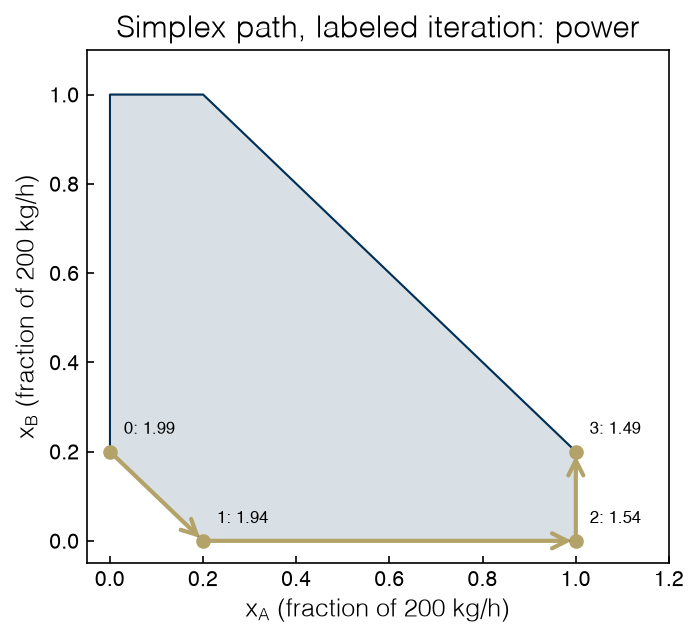

In [4]:
V = np.array([[0.2, 0.0], [1.0, 0.0], [1.0, 0.2], [0.2, 1.0], [0.0, 1.0], [0.0, 0.2]])
P = np.array([p[:2] for p in path])
fig, ax = plt.subplots(figsize=(5, 4.6))
ax.fill(V[:, 0], V[:, 1], alpha=0.15, color='C0')
ax.plot(*np.vstack([V, V[:1]]).T, 'C0-', lw=1)
for k in range(len(P) - 1):
    ax.annotate('', xy=P[k + 1], xytext=P[k], arrowprops=dict(arrowstyle='->', color='C3', lw=2))
for k, (p, x) in enumerate(zip(P, path)):
    ax.plot(*p, 'o', color='C3')
    ax.text(p[0] + 0.03, p[1] + 0.04, f'{k}: {c @ x:.2f}', fontsize=8)
ax.set_xlabel('$x_A$ (fraction of 200 kg/h)')
ax.set_ylabel('$x_B$ (fraction of 200 kg/h)')
ax.set_title('Simplex path, labeled iteration: power')
ax.set_xlim(-0.05, 1.2); ax.set_ylim(-0.05, 1.1);

The bottom row of the final tableau is not the only place where we can find prices. The vector $y = c_B^\top B^{-1}$ for the final basis holds one number per row:

In [5]:
y = c[basis_opt] @ np.linalg.inv(A[:, basis_opt])
print('row prices y (demand, cap A, cap B, cap C):', np.round(y, 3))
print('reduced costs:', dict(zip(names, np.round(T_opt[-1, :-1], 3))))

row prices y (demand, cap A, cap B, cap C): [ 1.45 -0.25  0.    0.  ]
reduced costs: {'x_A': np.float64(0.0), 'x_B': np.float64(0.0), 'x_C': np.float64(0.25), 's_A': np.float64(0.25), 's_B': np.float64(0.0), 's_C': np.float64(0.0)}


The price on the demand row is 1.45, which is the hydrogen price of Topic 1.4, and the capacity row of A carries $-0.25$, which is the capacity rent (negative because more capacity on that row *lowers* the cost). These are the duals, now seen as a by-product of the final basis.

:::{exercise}
:label: ex-t15-tableau

Start the tableau from the other expensive vertex, basis $\{x_B, x_C, s_A, s_C\}$ (B full, C at 0.2, power 1.79). How many pivots does Dantzig's rule need now, and which vertices does it visit? Then change the entering rule to *Bland's rule* (enter the lowest-index variable with a negative reduced cost) and compare the path from both starting points.
:::

## Checking against a solver

Our tableau code is a teaching tool. Production solvers use the **revised simplex method**, which keeps a factorization of $B$ instead of the whole tableau, treats simple bounds such as $x_i \le 1$ directly instead of adding slack rows, and usually runs the **dual simplex** variant, which keeps the reduced costs nonnegative and works toward feasibility. HiGHS, which we use through Pyomo and `scipy.optimize.linprog`, is a solver of this kind. Let's check that it agrees with the hand calculation, and see how many iterations it needs:

In [6]:
hs = linprog(c, A_eq=A, b_eq=b, bounds=[(0, None)] * 6, method='highs-ds', options={'presolve': False})
print('HiGHS dual simplex on the standard form:', hs.nit, 'iterations')
print('  x       ', np.round(hs.x, 3), '   ours:', np.round(path[-1], 3))
print('  y       ', np.round(hs.eqlin.marginals, 3), '   ours:', np.round(y, 3))
print('  r       ', np.round(hs.lower.marginals, 3), '   ours:', np.round(T_opt[-1, :-1], 3))
print('  nonzero ', [names[j] for j in range(6) if hs.x[j] > 1e-9],
      '   our final basis:', sorted((names[j] for j in basis_opt), key=names.index))

bnd = linprog(c[:3], A_eq=[np.ones(3)], b_eq=[1.2], bounds=[(0, 1)] * 3, method='highs-ds', options={'presolve': False})
print('HiGHS with the bounds handled directly:', bnd.nit, 'iteration(s), power', round(bnd.fun, 3))

rng = np.random.default_rng(1)
print('random LPs  min c.x  s.t.  A x >= b, x >= 0 (A, b, c positive):')
for m in (10, 50, 200, 800):
    n = 2 * m
    Ar, br, cr = rng.uniform(0, 1, (m, n)), rng.uniform(1, 2, m), rng.uniform(1, 2, n)
    rr = linprog(cr, A_ub=-Ar, b_ub=-br, bounds=[(0, None)] * n, method='highs-ds', options={'presolve': False})
    ri = linprog(cr, A_ub=-Ar, b_ub=-br, bounds=[(0, None)] * n, method='highs-ipm', options={'presolve': False})
    print(f'   {m:4d} rows, {n:5d} columns: simplex {rr.nit:4d} iterations, interior point {ri.nit:3d}, '
          f'same objective: {np.isclose(rr.fun, ri.fun)}')

HiGHS dual simplex on the standard form: 4 iterations
  x        [1.  0.2 0.  0.  0.8 1. ]    ours: [1.  0.2 0.  0.  0.8 1. ]
  y        [ 1.45 -0.25 -0.   -0.  ]    ours: [ 1.45 -0.25  0.    0.  ]
  r        [0.   0.   0.25 0.25 0.   0.  ]    ours: [0.   0.   0.25 0.25 0.   0.  ]
  nonzero  ['x_A', 'x_B', 's_B', 's_C']    our final basis: ['x_A', 'x_B', 's_B', 's_C']
HiGHS with the bounds handled directly: 1 iteration(s), power 1.49
random LPs  min c.x  s.t.  A x >= b, x >= 0 (A, b, c positive):
     10 rows,    20 columns: simplex    8 iterations, interior point   9, same objective: True
     50 rows,   100 columns: simplex   35 iterations, interior point  12, same objective: True
    200 rows,   400 columns: simplex  111 iterations, interior point  15, same objective: True


    800 rows,  1600 columns: simplex  401 iterations, interior point  20, same objective: True


HiGHS reaches the same vertex, the same row prices and the same reduced costs, and the variables it leaves nonzero are exactly the four basic variables of our final tableau (the optimum is not degenerate, so the basis is the set of nonzero variables). It takes 4 iterations on the standard form, and a single one when the capacity bounds are handled as bounds rather than as rows. On the random LPs, the simplex iteration count grows roughly in proportion to the number of rows: 8, 35, 111 and 401 iterations for 10 to 800 rows, while the number of candidate bases grows beyond anything countable.

This is the practical case for the simplex method. In the worst case it can visit an exponential number of vertices (Klee and Minty built LPs to force this in 1972), but in practice it usually only needs a small multiple of $m$ pivots. It also ends at a vertex with an explicit basis, which gives us the duals and makes it fast to re-solve after a small change (a "warm start"). Branch-and-bound (Topic 2.5) re-solves thousands of slightly changed LPs, so it relies heavily on warm starts.

The last column of the output shows the main alternative, the **interior-point method**. An interior-point method does not walk along the boundary at all. Instead, it replaces the bounds $x \ge 0$ by a **logarithmic barrier** and minimizes $c^\top x - \mu \sum_j \ln x_j$ subject to $Ax = b$. The barrier is infinite on the boundary, so it keeps every iterate strictly inside the feasible region. Each value of the barrier weight $\mu$ has its own minimizer, and as $\mu$ is driven toward zero these minimizers trace out a smooth curve through the interior, called the **central path**, which ends at an optimal vertex. Each iteration is a Newton step, which is more expensive than a pivot, but the number of iterations grows slowly with problem size: on the random LPs it goes from 9 to 20, while the simplex count goes from 8 to 401. Interior-point methods also have polynomial worst-case bounds. HiGHS offers both (`method='highs-ipm'` in `linprog`), and the interior-point method is usually followed by a *crossover* step to move the interior solution to a vertex and recover a basis. The same barrier idea applied to nonlinear problems is the method inside Ipopt, which we have been using for NLPs since Topic 1.3.

:::{exercise}
:label: ex-t15-solver-trace

Build the fleet LP with $N = 30$ stacks with specific energies spread evenly from 1.1 to 1.8, each of capacity 1, and demand $D = 12.5$. Solve it in standard form (slack rows for the capacities) with your tableau code, starting from a feasible basis of your choice, and with HiGHS. Compare the number of pivots, and check that both report the same demand price. Which stack is marginal?
:::

## Degeneracy

The simplex step assumed the ratio test gives a positive step, but this fails at a **degenerate** vertex, i.e. one where some basic variable is zero. A degenerate vertex has more active constraints than are needed to pin it down, so it can be described by several different bases. The water-electrolysis LP of Topic 1.2 has a vertex like this, so let's work it out.

The LP has four variables $(n_{\mathrm{H_2O}}, n_{\mathrm{H_2}}, n_{\mathrm{O_2}}, q)$ and three balances (H, O, charge), so every basis has three basic variables. Its feasible region is a segment with two vertices, "all water", $(1, 0, 0, 0)$, and "all split", $(0, 1, 0.5, 2)$. At "all water" only one variable is nonzero, so the other two basic variables must be zero, and they can be any two of the remaining three: three different bases describe the same point. We run the tableau simplex from each, at $U = E^0 + 0.05$ V, with energies in kJ.

In [7]:
F, DG0, E0 = el.F_CONST, el.DG0, el.E0
kn = ['n_H2O', 'n_H2', 'n_O2', 'q']
Ak = np.array([[2, 2, 0, 0], [1, 0, 2, 0], [0, -2, 0, 1]], dtype=float)
bk = np.array([2.0, 1.0, 0.0])

def kernel_cost(U):
    return np.array([-DG0, 0.0, 0.0, -F * U]) / 1e3            # kJ

U = E0 + 0.05
for start in ([0, 1, 2], [0, 2, 3], [0, 1, 3]):
    T0 = make_tableau(Ak, bk, kernel_cost(U), start)
    yk = kernel_cost(U)[start] @ np.linalg.inv(Ak[:, start])
    print(f"basis {{{', '.join(kn[j] for j in start)}}} at all-water: prices y (H, O, charge) = {np.round(yk, 2)} kJ/mol, "
          f"reduced costs {np.round(T0[-1, :-1], 2)}")
print()
T_k, basis_k, path_k = simplex(Ak, bk, kernel_cost(U), [0, 1, 2], kn)
print(f"-F U = {-F * U / 1e3:.2f} kJ/mol")

basis {n_H2O, n_H2, n_O2} at all-water: prices y (H, O, charge) = [-118.56    0.   -118.56] kJ/mol, reduced costs [ 0.    0.    0.   -4.82]
basis {n_H2O, n_O2, q} at all-water: prices y (H, O, charge) = [-118.56    0.   -123.39] kJ/mol, reduced costs [ 0.   -9.65  0.    0.  ]
basis {n_H2O, n_H2, q} at all-water: prices y (H, O, charge) = [-123.39    9.65 -123.39] kJ/mol, reduced costs [  0.    0.  -19.3   0. ]

           n_H2O    n_H2    n_O2       q     rhs
 n_H2O      1.00    0.00    0.00    0.50    1.00
  n_H2      0.00    1.00    0.00   -0.50    0.00
  n_O2      0.00    0.00    1.00   -0.25    0.00
  r_j       0.00    0.00    0.00   -4.82   z = -237.13
enter q (r = -4.82); ratio test: n_H2O 2.00 -> leave n_H2O, step 2.00

           n_H2O    n_H2    n_O2       q     rhs
     q      2.00    0.00    0.00    1.00    2.00
  n_H2      1.00    1.00    0.00    0.00    1.00
  n_O2      0.50    0.00    1.00    0.00    0.50
  r_j       9.65    0.00    0.00    0.00   z = -246.78
all reduced 

The three bases describe the same point, all water, with three different price vectors and three different sets of reduced costs. Each says that something can be improved by splitting water, but each attributes the improvement to a different variable (the charge $q$, the hydrogen $n_{\mathrm{H_2}}$, or the oxygen $n_{\mathrm{O_2}}$). This is why the duals of a degenerate vertex are **not unique**: a solver reports the prices of whichever basis it happened to stop on, and another solver, or the same one after a small change, may report different ones. Topic 1.4's exercise on the charge balance runs into exactly this. Duality theory, in {doc}`../2-nonlinear_mixed_integer/Topic2.3-Duality`, describes the whole set of valid prices.

From any of the three bases, one pivot reaches "all split", where the bottom row is nonnegative and the row prices are unique since the vertex is not degenerate. The price of the charge balance at this vertex is $-123.39$ kJ/mol, which is $-FU$, and the reduced cost of water is $+9.65$ kJ/mol, which tells us that at this voltage keeping a mole of water unsplit is priced out, since it would forgo $2FU - \Delta G^0 = 2F \times 0.05$ V.

At exactly $U = E^0$ the LP is degenerate in a second way: the objective is flat along the whole segment, so every reduced cost at the optimum is zero and every point of the segment (not only the two vertices) is optimal:

In [8]:
T_rev = make_tableau(Ak, bk, kernel_cost(E0), [0, 1, 2])
print('reduced costs at U = E0:', np.round(T_rev[-1, :-1], 6))

reduced costs at U = E0: [0. 0. 0. 0.]


A zero reduced cost on a nonbasic variable means it can enter the basis without changing the objective, and at $E^0$ this reflects the fact that the cell is indifferent between making hydrogen and leaving water alone, which is the definition of the reversible voltage.

Degenerate vertices come up often in practice, so this is more than a curiosity. At a degenerate vertex the ratio test can return a step of zero, so the basis changes while the point and the objective stay the same, and in rare cases a sequence of these zero steps returns to a basis already visited and the method **cycles** forever. **Bland's rule**, which always enters the lowest-index improving variable and breaks ratio-test ties by the lowest index, provably prevents cycling, although production solvers use cheaper safeguards such as small random perturbations of the bounds.

:::{exercise}
:label: ex-t15-degeneracy

Run the tableau simplex on the water LP at $U = E^0 - 0.05$ V from each of the three all-water bases. Do they agree on the answer? Do they agree on the reduced costs? Then compute the reduced cost of the extent of reaction, the direction $(-1, 1, \tfrac12, 2)$ along the segment, and show that it equals $\Delta G^0 - 2FU$ at every $U$, whichever basis you start from.
:::

## Summary

- The simplex method works on the standard form $\min c^\top x$, $Ax = b$, $x \ge 0$. Slack, surplus and split variables convert any LP to it.
- Choosing $m$ basic variables and setting the rest to zero gives a basic solution. The basic feasible solutions are the vertices: the fleet LP has 15 candidate bases and 6 BFSs, the six corners of its hexagon.
- One simplex iteration computes reduced costs $r_j = c_j - y^\top A_j$, enters a variable with $r_j < 0$, applies the ratio test, and pivots. A positive reduced cost means the activity is priced out. All $r_j \ge 0$ certifies a global optimum.
- On the fleet LP, the tableau walks from power 1.99 through 1.94 and 1.54 to the optimum 1.49 in three pivots. Its final row prices are $y = (1.45, -0.25, 0, 0)$, and the reduced costs price out stack C and A's spare capacity by 0.25 each. HiGHS agrees.
- At a degenerate vertex, several bases describe the same point and the duals are not unique. The water LP's all-water vertex has three such bases, and at $U = E^0$ every reduced cost is zero. Bland's rule prevents cycling.

## Additional Reading

- D. Bertsimas and J. N. Tsitsiklis, *Introduction to Linear Optimization*, Athena Scientific (1997). Chapter 3 develops the simplex method, degeneracy and anticycling rules in full.
- J. Nocedal and S. J. Wright, *Numerical Optimization*, 2nd ed., Springer (2006). Chapter 13 covers the revised simplex method as solvers implement it, and Chapter 14 interior-point methods for LP.
- A. Ravindran, K. M. Ragsdell and G. V. Reklaitis, *Engineering Optimization: Methods and Applications*, 2nd ed., Wiley (2006). The simplex steps in tableau form, in the maximization convention of the lectures.
- R. G. Bland, "New finite pivoting rules for the simplex method", *Mathematics of Operations Research* 2, 103–107 (1977).
- V. Klee and G. J. Minty, "How good is the simplex algorithm?", in O. Shisha (ed.), *Inequalities III*, Academic Press (1972), pp. 159–175.